# Mental Health Survey: Exploratory Data Analysis

**Dataset:** CDC mental health indicators (BRFSS and PRAMS surveys), 2011-2021

**Goal:** understand how adults' mentally unhealthy days vary over time, across states, and across demographic groups.

**Tools:** Python (pandas, matplotlib)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\DATASETS FOR PERSONAL PROJECTS\mental_health_data.csv\mental_health_data.csv',encoding = 'unicode_escape')

## Loading and understanding the data
Each row is a **summary of a group of survey respondents**, not one person, for example "Nevada, 2018, Female, average number of bad mental health days". The file has 13,200 rows and 23 columns.

It mixes **three different questions** (different measures, units and people), so they are analysed separately:

| Question | Unit | Who it covers |
|---|---|---|
| Recent mentally unhealthy days among adults | average days per month | all adults |
| At least 14 recent mentally unhealthy days | % | women aged 18-44 |
| Postpartum depressive symptoms | % | new mothers |

The columns that matter: `LocationDesc` (state), `YearStart` (year), `Stratification1` (group: Overall, Female, Male or a race/ethnicity group), `Question`, `DataValueType` and `DataValueUnit` (how the number was calculated and its unit), `DataValue` (the result), `LowConfidenceLimit` and `HighConfidenceLimit` (the range the true value likely falls in) and `DatavalueFootnote` (explains blank or flagged values). The other columns are ID codes or copies of these.

In [5]:
df.shape

(13200, 23)

In [6]:
df.head()

,YearStart,YearEnd,LocationAbbr,LocationDesc,DataSource,Topic,Question,DataValueUnit,DataValueType,DataValue,...,HighConfidenceLimit,StratificationCategory1,Stratification1,GeoLocation,LocationID,TopicID,QuestionID,DataValueTypeID,StratificationCategoryID1,StratificationID1
0,2018,2018,NV,Nevada,BRFSS,Mental Health,At least 14 recent mentally unhealthy days amo...,%,Crude Prevalence,21.6,...,26.8,Overall,Overall,POINT (-117.07184056399967 39.493240390000494),32,MTH,MTH2_0,CRDPREV,OVERALL,OVR
1,2020,2020,NV,Nevada,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Mean,4.1,...,5.8,Race/Ethnicity,"Black, non-Hispanic",POINT (-117.07184056399967 39.493240390000494),32,MTH,MTH1_0,MEAN,RACE,BLK
2,2018,2018,NV,Nevada,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Mean,5.0,...,5.6,Gender,Female,POINT (-117.07184056399967 39.493240390000494),32,MTH,MTH1_0,MEAN,GENDER,GENF
3,2019,2019,NV,Nevada,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Age-adjusted Mean,4.7,...,5.2,Overall,Overall,POINT (-117.07184056399967 39.493240390000494),32,MTH,MTH1_0,AGEADJMEAN,OVERALL,OVR
4,2017,2017,NV,Nevada,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Mean,3.5,...,3.9,Overall,Overall,POINT (-117.07184056399967 39.493240390000494),32,MTH,MTH1_0,MEAN,OVERALL,OVR


In [5]:
df.tail()

,YearStart,YearEnd,LocationAbbr,LocationDesc,DataSource,Topic,Question,DataValueUnit,DataValueType,DataValue,...,HighConfidenceLimit,StratificationCategory1,Stratification1,GeoLocation,LocationID,TopicID,QuestionID,DataValueTypeID,StratificationCategoryID1,StratificationID1
13195,2020,2020,WY,Wyoming,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Age-adjusted Mean,8.5,...,11.1,Race/Ethnicity,"Multiracial, non-Hispanic",POINT (-108.10983035299967 43.23554134300048),56,MTH,MTH1_0,AGEADJMEAN,RACE,MRC
13196,2020,2020,WY,Wyoming,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Age-adjusted Mean,3.9,...,4.3,Race/Ethnicity,"White, non-Hispanic",POINT (-108.10983035299967 43.23554134300048),56,MTH,MTH1_0,AGEADJMEAN,RACE,WHT
13197,2020,2020,WY,Wyoming,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Age-adjusted Mean,4.1,...,4.5,Overall,Overall,POINT (-108.10983035299967 43.23554134300048),56,MTH,MTH1_0,AGEADJMEAN,OVERALL,OVR
13198,2020,2020,WY,Wyoming,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Mean,5.1,...,6.7,Race/Ethnicity,Hispanic,POINT (-108.10983035299967 43.23554134300048),56,MTH,MTH1_0,MEAN,RACE,HIS
13199,2020,2020,WY,Wyoming,BRFSS,Mental Health,Recent mentally unhealthy days among adults ag...,Number,Mean,7.6,...,11.4,Race/Ethnicity,"Multiracial, non-Hispanic",POINT (-108.10983035299967 43.23554134300048),56,MTH,MTH1_0,MEAN,RACE,MRC


In [6]:
df.nunique()

YearStart                     11
YearEnd                       11
LocationAbbr                  55
LocationDesc                  55
DataSource                     2
Topic                          1
Question                       3
DataValueUnit                  2
DataValueType                  3
DataValue                    310
DataValueAlt                 310
DatavalueFootnote              4
LowConfidenceLimit           234
HighConfidenceLimit          407
StratificationCategory1        3
Stratification1                8
GeoLocation                   54
LocationID                    55
TopicID                        1
QuestionID                     3
DataValueTypeID                3
StratificationCategoryID1      3
StratificationID1              8
dtype: int64

In [4]:
df.isnull().sum()

YearStart                        0
YearEnd                          0
LocationAbbr                     0
LocationDesc                     0
DataSource                       0
Topic                            0
Question                         0
DataValueUnit                    0
DataValueType                    0
DataValue                     2484
DataValueAlt                  2484
DatavalueFootnote            10639
LowConfidenceLimit            2484
HighConfidenceLimit           2484
StratificationCategory1          0
Stratification1                  0
GeoLocation                     78
LocationID                       0
TopicID                          0
QuestionID                       0
DataValueTypeID                  0
StratificationCategoryID1        0
StratificationID1                0
dtype: int64

**Missing values:** `DataValue` and both confidence limits are blank in the same 2,484 rows (about 19%), and the footnote column explains why: the sample was too small to be reliable, or no data was available. These are suppressed or unavailable estimates, not entry mistakes, so I do not fill them in.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   YearStart                  13200 non-null  int64  
 1   YearEnd                    13200 non-null  int64  
 2   LocationAbbr               13200 non-null  str    
 3   LocationDesc               13200 non-null  str    
 4   DataSource                 13200 non-null  str    
 5   Topic                      13200 non-null  str    
 6   Question                   13200 non-null  str    
 7   DataValueUnit              13200 non-null  str    
 8   DataValueType              13200 non-null  str    
 9   DataValue                  10716 non-null  float64
 10  DataValueAlt               10716 non-null  float64
 11  DatavalueFootnote          2561 non-null   str    
 12  LowConfidenceLimit         10716 non-null  float64
 13  HighConfidenceLimit        10716 non-null  float64
 14  S

*Data types look right: year, values and confidence limits are numeric and everything else is text, so nothing needs converting.*

## Checking the data before cleaning
Before dropping any columns, I check that they are truly redundant and that there are no duplicate rows.

In [5]:
# 1. duplicate rows (whole row, and on the columns that identify a row)
key = ["LocationDesc", "YearStart", "Question", "DataValueType", "DataValueUnit", "Stratification1"]
print("fully duplicated rows:", df.duplicated().sum())
print("duplicated on identifying columns:", df.duplicated(subset=key).sum())

# 2. are the columns I plan to drop really redundant?
print("YearStart != YearEnd:", (df["YearStart"] != df["YearEnd"]).sum())
print("unique Topic values:", df["Topic"].nunique())
print("QuestionID per Question (max):", df.groupby("Question")["QuestionID"].nunique().max())
print("DataValueAlt same as DataValue:", (df["DataValue"].fillna(-1) == df["DataValueAlt"].fillna(-1)).all())

fully duplicated rows: 0
duplicated on identifying columns: 0
YearStart != YearEnd: 0
unique Topic values: 1
QuestionID per Question (max): 1
DataValueAlt same as DataValue: True


*No duplicate rows, so every row is a unique location + year + group + question + measure type. `YearEnd` always equals `YearStart`, `Topic` has a single value, the ID columns just repeat their text columns, and `DataValueAlt` is a copy of `DataValue`. All of them are safe to drop.*

In [12]:
cols_to_drop = ["YearEnd", "Topic", "TopicID", "DataValueAlt", "LocationID",
                "QuestionID", "DataValueTypeID", "StratificationCategoryID1",
                "StratificationID1"]

df = df.drop(columns=cols_to_drop)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   YearStart                13200 non-null  int64  
 1   LocationAbbr             13200 non-null  str    
 2   LocationDesc             13200 non-null  str    
 3   DataSource               13200 non-null  str    
 4   Question                 13200 non-null  str    
 5   DataValueUnit            13200 non-null  str    
 6   DataValueType            13200 non-null  str    
 7   DataValue                10716 non-null  float64
 8   DatavalueFootnote        2561 non-null   str    
 9   LowConfidenceLimit       10716 non-null  float64
 10  HighConfidenceLimit      10716 non-null  float64
 11  StratificationCategory1  13200 non-null  str    
 12  Stratification1          13200 non-null  str    
 13  GeoLocation              13122 non-null  str    
dtypes: float64(3), int64(1), str(10)


## Focusing on question 1 and checking missing values
I focus on **question 1** (adults, average mentally unhealthy days). It has the most rows (9,570), covers 2011-2021 and includes gender and race/ethnicity groups. Question 2 has no gender comparison and much more missing data, and question 3 has a single year (both are covered at the end). Here I check where the blanks are, by group and by year.

In [9]:
q1 = df[df["Question"] == "Recent mentally unhealthy days among adults aged >= 18 years"].copy()
print(q1.shape)

q1["missing"] = q1["DataValue"].isna()
print(q1.groupby("Stratification1")["missing"].mean().round(2))
print(q1.groupby("YearStart")["missing"].mean().round(2))

(9570, 23)
Stratification1
Black, non-Hispanic          0.28
Female                       0.02
Hispanic                     0.13
Male                         0.02
Multiracial, non-Hispanic    0.19
Other, non-Hispanic          0.12
Overall                      0.02
White, non-Hispanic          0.08
Name: missing, dtype: float64
YearStart
2011    0.10
2012    0.35
2013    0.10
2014    0.09
2015    0.10
2016    0.08
2017    0.07
2018    0.07
2019    0.09
2020    0.07
2021    0.06
Name: missing, dtype: float64


*In question 1, blanks are concentrated in the race/ethnicity groups (up to 28% for Black, non-Hispanic) and in 2012 (35%). Overall, Female and Male are about 98% complete. Blanks are left as NaN, not filled.*

## More data quality checks
All checks below use `q1` (question 1: adults, average mentally unhealthy days).

In [10]:
# are the values realistic? (days in a month must be between 0 and 30)
print(q1["DataValue"].describe())

count    8551.000000
mean        4.302584
std         1.234738
min         1.200000
25%         3.500000
50%         4.100000
75%         4.900000
max        11.300000
Name: DataValue, dtype: float64


*Values range from about 1 to 11 days with a mean around 4.3, so nothing impossible. The highest values are most likely small groups in small places, where estimates are shakier.*

In [11]:
# do the confidence limits make sense? (low <= value <= high)
print("low limit above value:", (q1["LowConfidenceLimit"] > q1["DataValue"]).sum())
print("high limit below value:", (q1["HighConfidenceLimit"] < q1["DataValue"]).sum())

low limit above value: 0
high limit below value: 0


*Both are 0, so every estimate sits inside its own confidence range.*

In [12]:
# are the labels clean? (typos or stray spaces would split one group into two)
print(q1["Stratification1"].unique())
print("groups with stray spaces:", (q1["Stratification1"] != q1["Stratification1"].str.strip()).sum())
print("unique locations:", q1["LocationDesc"].nunique())

<StringArray>
[      'Black, non-Hispanic',                    'Female',
                   'Overall',                  'Hispanic',
 'Multiracial, non-Hispanic',       'Other, non-Hispanic',
                      'Male',       'White, non-Hispanic']
Length: 8, dtype: str
groups with stray spaces: 0
unique locations: 55


*There are 8 clean groups: Overall, Female, Male and 5 race/ethnicity groups. The 55 locations are the 50 states, DC, and 4 extra rows (United States, Guam, Puerto Rico, Virgin Islands). The extra rows must be kept out of state comparisons later.*

In [13]:
x = q1[(q1["LocationDesc"] == "Nevada") & (q1["YearStart"] == 2018) & (q1["Stratification1"] == "Overall")]
print(x[["DataValueType", "DataValue", "LowConfidenceLimit", "HighConfidenceLimit"]])

          DataValueType  DataValue  LowConfidenceLimit  HighConfidenceLimit
8532               Mean        4.0                 3.6                  4.4
8579  Age-adjusted Mean        4.1                 3.7                  4.5


In [ ]:
# do the two versions agree? (same location + year + group, Mean vs Age-adjusted Mean)
both = q1.pivot_table(
    index=["LocationDesc", "YearStart", "Stratification1"],
    columns="DataValueType",
    values="DataValue",
).dropna()

both["gap"] = (both["Mean"] - both["Age-adjusted Mean"]).abs()

print("slots where both versions exist:", len(both))
print(both[["Mean", "Age-adjusted Mean"]].corr().round(3))
print(both["gap"].describe().round(2))
print("within 0.2 days:", round((both["gap"] <= 0.2).mean(), 2))
print("within 0.5 days:", round((both["gap"] <= 0.5).mean(), 2))

slots where both versions exist: 4109
DataValueType       Mean  Age-adjusted Mean
DataValueType                              
Mean               1.000              0.964
Age-adjusted Mean  0.964              1.000
count    4109.00
mean        0.20
std         0.26
min         0.00
25%         0.10
50%         0.10
75%         0.30
max         3.00
Name: gap, dtype: float64
within 0.2 days: 0.63
within 0.5 days: 0.93


Each result appears **twice** in question 1, once as `Mean` and once as `Age-adjusted Mean` (Nevada 2018 above). Using both would count everything twice, so I use one. The age-adjusted version recalculates every state with the same standard age mix, so a state does not look better or worse just because it is older or younger. The CDC already calculated it, I only chose which rows to use. I use it because most of this analysis compares states and groups.

Where both versions exist they are very close (correlation 0.96, typical gap 0.1 days), so the choice does not change the story.

In [13]:
df.describe()

,YearStart,DataValue,LowConfidenceLimit,HighConfidenceLimit
count,13200.000000,10716.00000,10716.000000,10716.000000
mean,2015.979167,6.74804,5.244336,8.495502
std,3.172196,5.47081,4.131193,7.545289
min,2011.000000,1.20000,0.700000,1.800000
25%,2013.000000,3.60000,3.000000,4.200000
50%,2016.000000,4.40000,3.700000,5.100000
75%,2019.000000,6.40000,4.900000,8.700000
max,2021.000000,41.20000,27.800000,59.400000


# Exploratory Data Analysis

## Setup: which rows I analyse
- **Question 1 only, Age-adjusted Mean only:** 4,785 rows, one per location + year + group.
- **The 50 states + DC only:** 4,488 rows, 51 locations. I removed Guam, Puerto Rico and the Virgin Islands (territories, with Puerto Rico and the Virgin Islands having far more missing data than the states) and the "United States" row, which is a summary and not a state. That row is the CDC's own benchmark, a median of the state values, so it is not a true national average (each state counts once regardless of population). I only use it as a reference.

`states` is the working table from here on. Charts show the **typical state**, the median across states, so a few unusual states do not pull the line.

In [14]:
# keep only one measure type, so each location + year + group appears once
q1_adj = q1[q1["DataValueType"] == "Age-adjusted Mean"].copy()
print(q1_adj.shape)

# separate the 50 states + DC from the summary/territory rows
non_states = ["United States", "Guam", "Puerto Rico", "Virgin Islands"]
states = q1_adj[~q1_adj["LocationDesc"].isin(non_states)].copy()
print(states.shape)
print(states["LocationDesc"].nunique())

(4785, 24)
(4488, 24)
51


## Trend over time
*Has the average number of bad mental health days changed?* For each year, the median across states for the Overall group.

YearStart
2011    3.7
2012    3.9
2013    3.7
2014    3.7
2015    3.7
2016    3.8
2017    4.0
2018    4.1
2019    4.5
2020    4.4
2021    4.8
Name: DataValue, dtype: float64


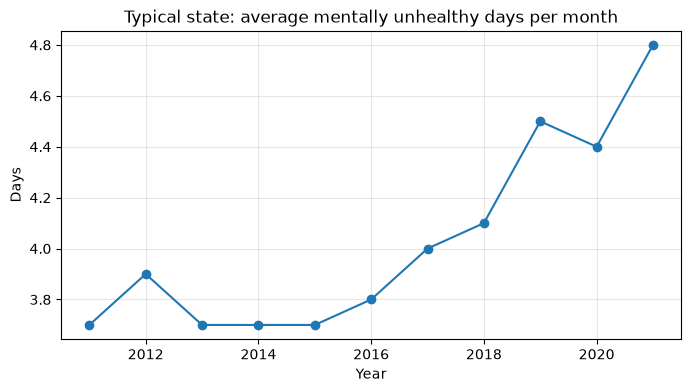

In [ ]:
# only the "Overall" group, across the 51 states
overall = states[states["Stratification1"] == "Overall"]

# one number per year: the median across states
trend = overall.groupby("YearStart")["DataValue"].median()
print(trend)

trend.plot(marker="o", figsize=(8, 4), title="Typical state: average mentally unhealthy days per month")
plt.xlabel("Year")
plt.ylabel("Days")
plt.grid(alpha=0.3)
plt.show()

The typical state went from about **3.7** bad mental health days a month in 2011 to **4.8** in 2021 (about +1.1 days). It was flat until about 2015 and then rose, with 2019 (4.5) the first big jump. The y-axis starts near 3.7, which makes the rise look steeper than the actual change. The data shows that it rose, not why.

In [16]:
# Overall group, one row per state, one column per year
pivot = states[states["Stratification1"] == "Overall"].pivot(
    index="LocationDesc", columns="YearStart", values="DataValue"
)

# change from 2011 to 2021 for each state
change = (pivot[2021] - pivot[2011]).dropna()

print((change > 0).sum(), "of", len(change), "states increased")
print(change.describe())

50 of 50 states increased
count    50.000000
mean      1.066000
std       0.394146
min       0.200000
25%       0.800000
50%       1.000000
75%       1.300000
max       2.000000
dtype: float64


Is the rise driven by just a few states? Comparing each state with itself (2021 minus 2011), **all 50 states with data in both years were higher in 2021**. The smallest increase is +0.2, the median +1.0 and the largest +2.0. One state has no 2021 value, so it cannot be compared. This only compares two years, so it says nothing about the years in between.

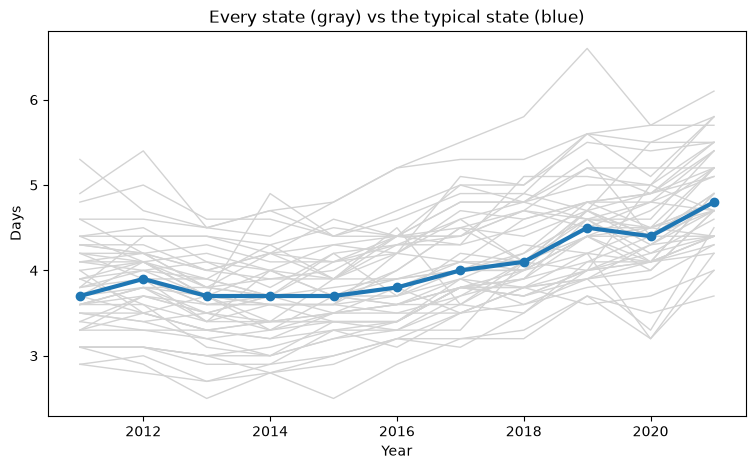

In [17]:
pivot = states[states["Stratification1"] == "Overall"].pivot(
    index="LocationDesc", columns="YearStart", values="DataValue"
)

ax = pivot.T.plot(legend=False, color="lightgray", figsize=(9, 5), linewidth=1)
pivot.median().plot(ax=ax, color="tab:blue", linewidth=3, marker="o")
plt.title("Every state (gray) vs the typical state (blue)")
plt.xlabel("Year")
plt.ylabel("Days")
plt.show()

Each gray line is one state and the blue line is the typical state. Most states drift upward together, so the rise is widespread, but individual states fluctuate a lot from year to year. States also differ in level, with some consistently higher than others.

## Which states are highest and lowest?
Ranking the states for **2021** (the latest year), Overall group, with their confidence ranges.

In [21]:
latest = states[(states["Stratification1"] == "Overall") & (states["YearStart"] == 2021)]
latest = latest.dropna(subset=["DataValue"])

ranked = latest.sort_values("DataValue", ascending=False)[
    ["LocationDesc", "DataValue", "LowConfidenceLimit", "HighConfidenceLimit"]
]
print(ranked.head(5))
print(ranked.tail(5))

        LocationDesc  DataValue  LowConfidenceLimit  HighConfidenceLimit
12844  West Virginia        6.1                 5.8                  6.4
582         Arkansas        5.8                 5.4                  6.2
10593      Tennessee        5.8                 5.4                  6.2
448          Alabama        5.8                 5.4                  6.2
4872       Louisiana        5.7                 5.3                  6.1
       LocationDesc  DataValue  LowConfidenceLimit  HighConfidenceLimit
3691       Illinois        4.2                 3.8                  4.6
8594       New York        4.2                 4.1                  4.4
7206   North Dakota        4.0                 3.7                  4.3
10336  South Dakota        4.0                 3.5                  4.4
3120         Hawaii        3.7                 3.4                  3.9


**Highest in 2021:** West Virginia (6.1), then Arkansas, Tennessee and Alabama (5.8) and Louisiana (5.7). **Lowest:** Hawaii (3.7), South Dakota and North Dakota (4.0), New York and Illinois (4.2).

Within each group the ranges overlap a lot, so those states cannot be reliably ranked against each other. But the top five are clearly above the bottom five: the lowest limit among the top five is 5.3 and the highest limit among the bottom five is 4.6.

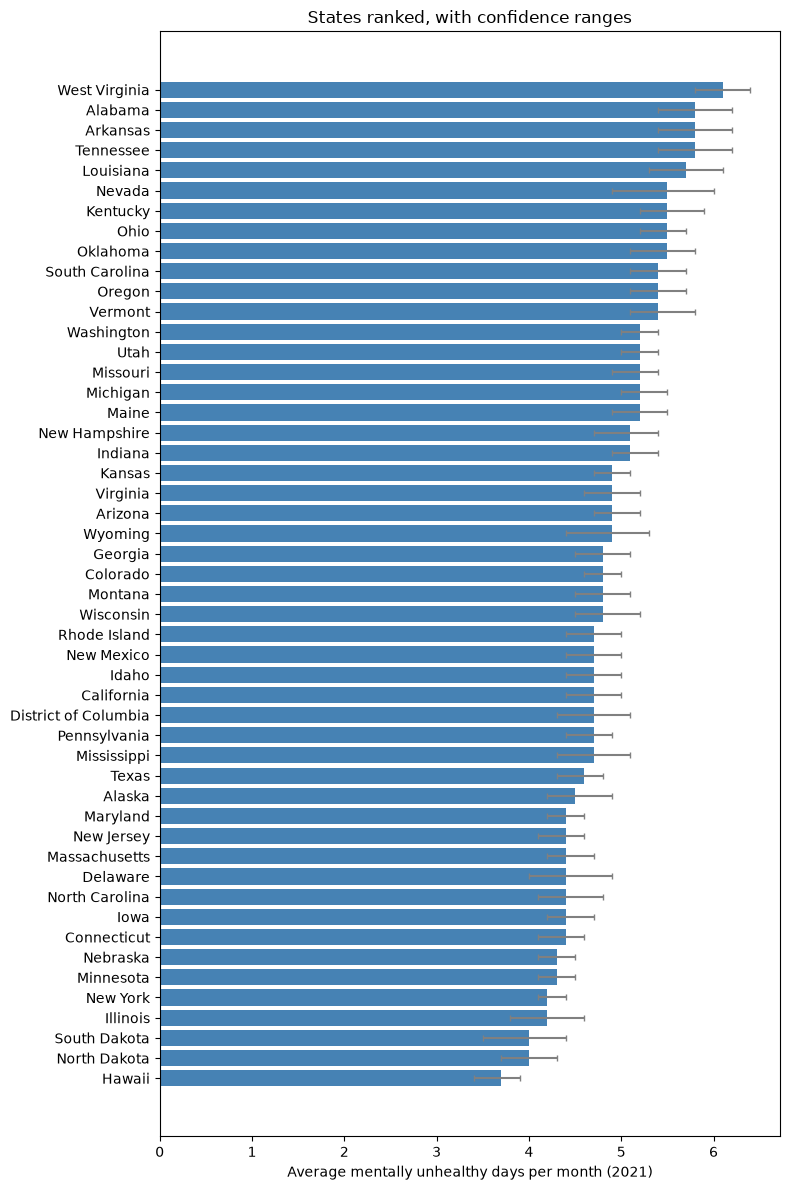

In [23]:
ranked_plot = ranked.sort_values("DataValue")
err_low = ranked_plot["DataValue"] - ranked_plot["LowConfidenceLimit"]
err_high = ranked_plot["HighConfidenceLimit"] - ranked_plot["DataValue"]

plt.figure(figsize=(8, 12))
plt.barh(ranked_plot["LocationDesc"], ranked_plot["DataValue"],
         xerr=[err_low, err_high], color="steelblue", ecolor="gray", capsize=2)
plt.xlabel("Average mentally unhealthy days per month (2021)")
plt.title("States ranked, with confidence ranges")
plt.tight_layout()
plt.show()

In [15]:
us = q1_adj[(q1_adj["LocationDesc"] == "United States") &
            (q1_adj["Stratification1"] == "Overall") &
            (q1_adj["YearStart"] == 2021)]
print(us[["DataValue", "DatavalueFootnote"]])

       DataValue                                  DatavalueFootnote
11274        4.8  US estimate/number is based on fewer than 50 s...


The CDC's "United States" row for 2021 is also 4.8, with a footnote saying it is based on fewer than 50 states + DC. It matches the typical-state line in the chart below.

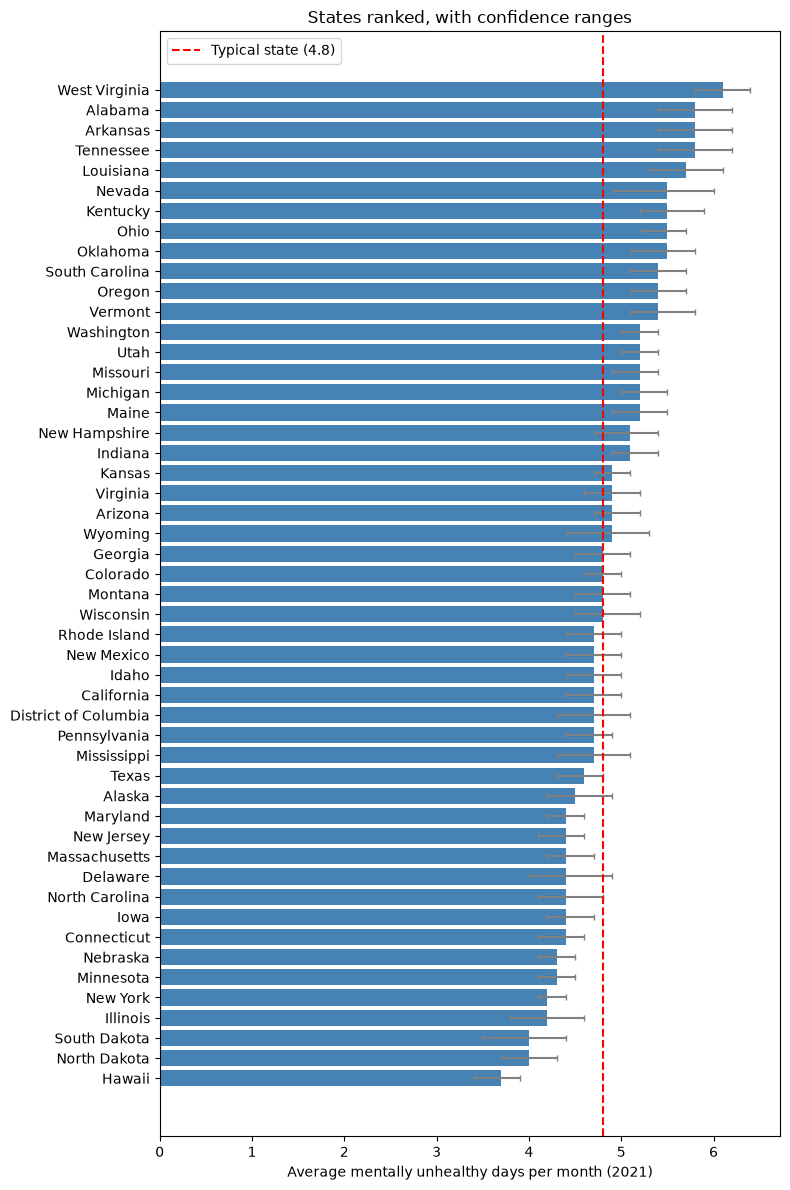

In [24]:
ranked_plot = ranked.sort_values("DataValue")
err_low = ranked_plot["DataValue"] - ranked_plot["LowConfidenceLimit"]
err_high = ranked_plot["HighConfidenceLimit"] - ranked_plot["DataValue"]

plt.figure(figsize=(8, 12))
plt.barh(ranked_plot["LocationDesc"], ranked_plot["DataValue"],
         xerr=[err_low, err_high], color="steelblue", ecolor="gray", capsize=2)

# NEW: dashed line at the typical (median) state
typical = ranked_plot["DataValue"].median()
plt.axvline(typical, color="red", linestyle="--", label=f"Typical state ({typical:.1f})")
plt.legend()

plt.xlabel("Average mentally unhealthy days per month (2021)")
plt.title("States ranked, with confidence ranges")
plt.tight_layout()
plt.show()

In [ ]:
# how many states are clearly above or below the typical state in 2021?
typical = latest["DataValue"].median()
clearly_above = (latest["LowConfidenceLimit"] > typical).sum()
clearly_below = (latest["HighConfidenceLimit"] < typical).sum()

print("typical state:", typical)
print("states with a 2021 value:", len(latest))
print("clearly above:", clearly_above)
print("clearly below:", clearly_below)
print("cannot be told apart from typical:", len(latest) - clearly_above - clearly_below)

no_2021 = states[(states["Stratification1"] == "Overall") & (states["YearStart"] == 2021)
                 & states["DataValue"].isna()]["LocationDesc"].tolist()
print("no 2021 value:", no_2021)

typical state: 4.8
states with a 2021 value: 50
clearly above: 18
clearly below: 12
cannot be told apart from typical: 20
no 2021 value: ['Florida']


The red dashed line is the typical state (4.8). Many states near the middle have ranges that cross the line, so they cannot be called above or below it. This is approximate, since the limits are rounded to one decimal. Florida is the only state with no 2021 value. The ranking is a snapshot of one year, not a trend.

## Gender differences
Female vs Male, typical state, every year.

Stratification1  Female  Male
YearStart                    
2011               4.30   3.3
2012               4.40   3.3
2013               4.20   3.1
2014               4.20   3.1
2015               4.20   3.1
2016               4.40   3.2
2017               4.70   3.3
2018               4.90   3.5
2019               5.30   3.7
2020               5.40   3.5
2021               5.75   3.9


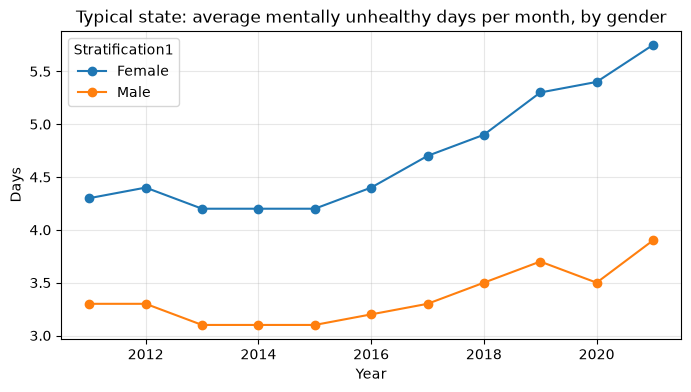

In [16]:
gender = states[states["Stratification1"].isin(["Female", "Male"])]

gender_trend = gender.groupby(["YearStart", "Stratification1"])["DataValue"].median().unstack()
print(gender_trend)

gender_trend.plot(marker="o", figsize=(8, 4),
                  title="Typical state: average mentally unhealthy days per month, by gender")
plt.xlabel("Year")
plt.ylabel("Days")
plt.grid(alpha=0.3)
plt.show()

Women reported more bad days than men **in every year**. Both rose, but the typical value for women went from 4.3 to 5.75 (+1.45) and for men from 3.3 to 3.9 (+0.6), so the gap grew from about 1.0 day in 2011 to about 1.85 days in 2021. (2021 Female is 5.75 because 50 states have a value, so the median is the average of the two middle states.) This describes the gap, not its cause.

## Race and ethnicity differences
Same idea with one line per group. The second table shows how many states each value is based on.

Stratification1  Black, non-Hispanic  Hispanic  Multiracial, non-Hispanic  Other, non-Hispanic  White, non-Hispanic
YearStart                                                                                                          
2011                            4.20      3.90                       6.00                  4.0                 3.70
2012                            4.30      3.85                       6.10                  3.7                 3.80
2013                            4.30      3.70                       5.30                  3.3                 3.70
2014                            4.10      3.60                       5.60                  3.4                 3.70
2015                            3.95      3.60                       5.65                  3.6                 3.70
2016                            4.05      3.60                       6.00                  3.9                 3.90
2017                            4.10      3.70                       6.0

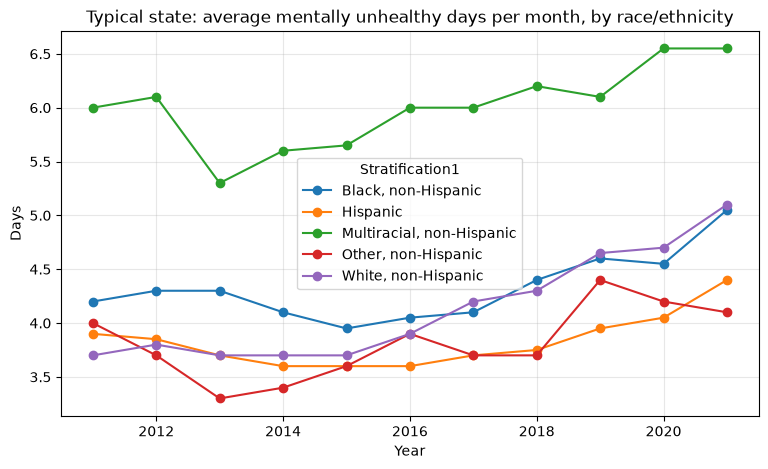

In [17]:
race = states[~states["Stratification1"].isin(["Overall", "Female", "Male"])]

race_trend = race.groupby(["YearStart", "Stratification1"])["DataValue"].median().unstack()
race_n = race.groupby(["YearStart", "Stratification1"])["DataValue"].count().unstack()

print(race_trend.round(2).to_string())
print(race_n.to_string())

race_trend.plot(marker="o", figsize=(9, 5),
                title="Typical state: average mentally unhealthy days per month, by race/ethnicity")
plt.xlabel("Year")
plt.ylabel("Days")
plt.grid(alpha=0.3)
plt.show()

Multiracial respondents report the most bad days in every year (about 5.3 to 6.55), and White, non-Hispanic is nearly complete (50-51 states every year). Most groups were higher in 2021 than in 2011, though the lines move around from year to year and "Other" is especially jumpy. Black and White respondents were apart in 2011 (4.2 vs 3.7) and almost equal in 2021 (5.05 vs 5.1).

**Caution:** each line is a median over a different set of states (as few as 39 for Black, non-Hispanic and 42 for Multiracial), so small moves can reflect which states reported rather than real change.

## Question 2: women aged 18-44 with 14+ bad days
The unit is the % of women. There is only one measure type (crude prevalence), so no age-adjusted choice to make, and no gender comparison since everyone in this question is a woman.

(3575, 23) (3366, 23)
Stratification1
Black, non-Hispanic          0.43
Hispanic                     0.41
Multiracial, non-Hispanic    0.77
Other, non-Hispanic          0.67
Overall                      0.00
White, non-Hispanic          0.01
Name: missing, dtype: float64
YearStart
2011    14.5
2012    15.2
2013    14.3
2014    14.4
2015    14.6
2016    15.7
2017    17.1
2018    18.0
2019    20.6
2020    20.7
2021    23.9
Name: DataValue, dtype: float64


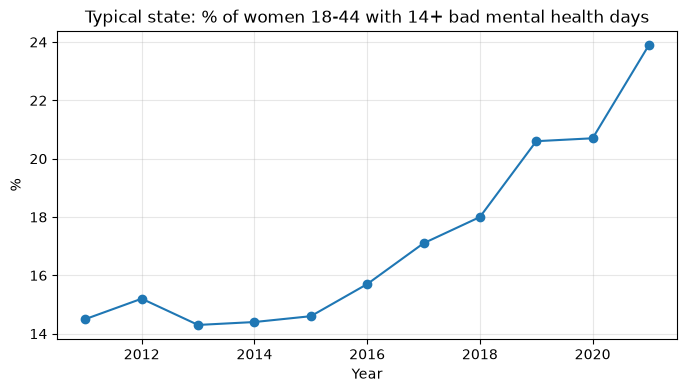

In [18]:
# question 2, states only
q2 = df[df["Question"] == "At least 14 recent mentally unhealthy days among women aged 18-44 years"].copy()
q2_states = q2[~q2["LocationDesc"].isin(["United States", "Guam", "Puerto Rico", "Virgin Islands"])].copy()
print(q2.shape, q2_states.shape)

# how much is missing, by group
q2_states["missing"] = q2_states["DataValue"].isna()
print(q2_states.groupby("Stratification1")["missing"].mean().round(2))

# overall trend: typical state, % of women with 14+ bad days
q2_overall = q2_states[q2_states["Stratification1"] == "Overall"]
q2_trend = q2_overall.groupby("YearStart")["DataValue"].median()
print(q2_trend)

q2_trend.plot(marker="o", figsize=(8, 4),
              title="Typical state: % of women 18-44 with 14+ bad mental health days")
plt.xlabel("Year")
plt.ylabel("%")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# how many states are behind each race/ethnicity value in question 2?
race_q2 = q2_states[q2_states["Stratification1"] != "Overall"]
q2_n = race_q2.groupby(["YearStart", "Stratification1"])["DataValue"].count().unstack()
print(q2_n.to_string())

Stratification1  Black, non-Hispanic  Hispanic  Multiracial, non-Hispanic  Other, non-Hispanic  White, non-Hispanic
YearStart                                                                                                          
2011                              29        22                          4                    9                   51
2012                              29        23                          5                   11                   50
2013                              24        24                          4                    8                   50
2014                              23        19                          2                    5                   50
2015                              22        20                          4                    7                   50
2016                              29        31                         14                   18                   51
2017                              33        36                         1

The typical state went from about **14.5%** of women with 14+ bad days in 2011 to **23.9%** in 2021, flat until about 2015 and then rising, the same shape as question 1. The Overall group is complete, but race/ethnicity is very patchy: Multiracial is 77% missing and Other 67%, and the table above shows these groups are based on as few as 2 states in a year. Lines for them would mostly show which states reported, so I only report the Overall trend for this question.

## Question 3: postpartum depressive symptoms

In [19]:
q3 = df[df["Question"].str.contains("Postpartum")].copy()

print(q3.shape)
print(q3["YearStart"].unique())
print(q3["Stratification1"].unique())
print(q3["DataValue"].isna().sum(), "missing,", q3["DataValue"].notna().sum(), "with a value")
print(q3["DataValue"].describe())

(55, 23)
[2011]
<StringArray>
['Overall']
Length: 1, dtype: str
32 missing, 23 with a value
count    23.000000
mean     10.847826
std       2.742240
min       6.900000
25%       9.400000
50%      10.300000
75%      12.150000
max      18.000000
Name: DataValue, dtype: float64


This question has only 55 rows: one per location, for a single year (2011) and a single group (Overall). 32 are blank ("no data available") and 23 have a value (about 7% to 18%, median about 10%). It comes from a different survey (PRAMS) and cannot show a trend or a group comparison, so it is left out of the analysis.

## Questions I answered
1. **Has the average number of bad mental health days changed over time?** Yes. The typical state rose from about 3.7 days a month in 2011 to 4.8 in 2021, and every state with data in both years was higher in 2021. For women aged 18-44, the share with 14+ bad days rose from about 14.5% to 23.9%.
2. **Which states are highest and lowest?** In 2021, West Virginia, Arkansas, Tennessee, Alabama and Louisiana are highest, and Hawaii, the Dakotas, New York and Illinois are lowest. The top five are clearly above the bottom five, but states within a group cannot be reliably ranked.
3. **How do gender and race/ethnicity groups differ?** Women report more bad days than men in every year, and the gap grew from about 1.0 to 1.85 days. Multiracial respondents report the most bad days, but the race/ethnicity comparison is less reliable because many states have no value for these groups.

## Limitations
- Each row summarises a sample of people, and BRFSS surveys a new sample of adults each year, so the results describe state averages, not changes in individuals.
- The data shows what changed, not why. No causes are claimed.
- Many estimates are blank (suppressed or unavailable), especially for race/ethnicity groups, and the set of reporting states changes by group and year.
- The "typical state" is a median of states, not a population-weighted national average.
- The file does not say which standard age mix was used for the age-adjusted values.
- `GeoLocation` (one fixed point per state) was not used, since the analysis is by state name.